# 7. Imbalanced Data Handling

## 1. Introduction

Credit card fraud detection is typically a highly imbalanced
classification problem.

The number of legitimate transactions may be much greater
than the number of fraudulent transactions.

This imbalance can cause a classifier to favor the majority
class.

This notebook investigates several strategies for handling
class imbalance.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

from sklearn.model_selection import train_test_split

from src.config import (
    CLEANED_DATA_PATH,
    TARGET_COLUMN,
    RANDOM_STATE,
    TEST_SIZE,
)

df = pd.read_csv(CLEANED_DATA_PATH)

X = df.drop(columns=[TARGET_COLUMN])

y = df[TARGET_COLUMN]

X_development, X_test, y_development, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_validation, y_train, y_validation = train_test_split(
    X_development,
    y_development,
    test_size=0.20,
    stratify=y_development,
    random_state=RANDOM_STATE
)

print("Training Class Distribution:")
print(Counter(y_train))

Training Class Distribution:
Counter({0: 181961, 1: 315})


## 2. Class Imbalance Analysis

The training target distribution is examined.

The imbalance ratio is calculated as:

Imbalance Ratio =
Number of Majority Class Samples /
Number of Minority Class Samples

A high imbalance ratio indicates that the minority class
is significantly underrepresented.

In [2]:
class_counts = Counter(y_train)

majority_count = max(class_counts.values())

minority_count = min(class_counts.values())

imbalance_ratio = majority_count / minority_count

print("Class Counts:", class_counts)

print("Imbalance Ratio:", imbalance_ratio)

Class Counts: Counter({0: 181961, 1: 315})
Imbalance Ratio: 577.6539682539683


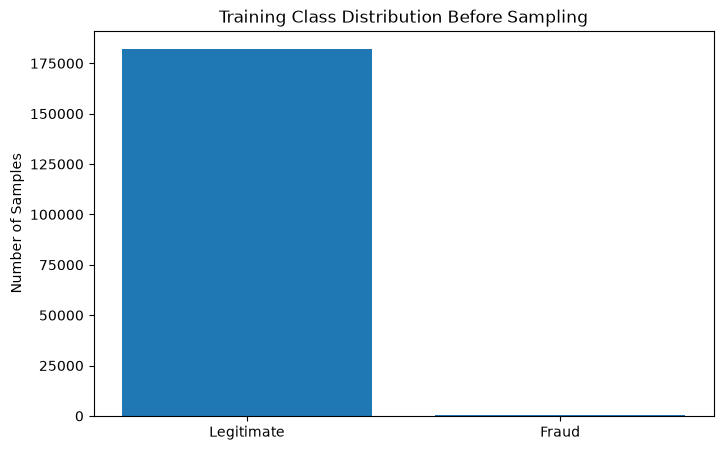

In [3]:
plt.figure(figsize=(8, 5))

plt.bar(
    ["Legitimate", "Fraud"],
    [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ]
)

plt.title("Training Class Distribution Before Sampling")

plt.ylabel("Number of Samples")

plt.show()

## 3. Sampling Techniques

The following methods will be investigated:

### 3.1 SMOTE

Synthetic Minority Over-sampling Technique creates synthetic
minority-class observations using nearest neighbors.

### 3.2 Random Over Sampling

Randomly duplicates observations from the minority class.

### 3.3 Random Under Sampling

Reduces the number of majority-class observations.

### 3.4 No Sampling

Uses the original class distribution.

All sampling operations must be restricted to training data.

In [4]:
from src.imbalance import create_sampler

sampling_methods = [
    "smote",
    "random_over",
    "random_under",
    "none"
]

sampling_results = {}

for method in sampling_methods:

    sampler = create_sampler(
        method=method,
        random_state=RANDOM_STATE
    )

    if method == "none":

        X_resampled = X_train.copy()
        y_resampled = y_train.copy()

    else:

        X_resampled, y_resampled = sampler.fit_resample(
            X_train,
            y_train
        )

    sampling_results[method] = {
        "X": X_resampled,
        "y": y_resampled,
        "distribution": Counter(y_resampled)
    }

    print(f"\nMethod: {method}")

    print("Before:", Counter(y_train))

    print("After:", Counter(y_resampled))


Method: smote
Before: Counter({0: 181961, 1: 315})
After: Counter({0: 181961, 1: 181961})

Method: random_over
Before: Counter({0: 181961, 1: 315})
After: Counter({0: 181961, 1: 181961})

Method: random_under
Before: Counter({0: 181961, 1: 315})
After: Counter({0: 315, 1: 315})

Method: none
Before: Counter({0: 181961, 1: 315})
After: Counter({0: 181961, 1: 315})


## 4. Sampling Results Comparison

The number of observations in each class is compared
before and after applying each sampling strategy.

The purpose of this comparison is to understand how
each strategy changes the training distribution.

Balanced class counts do not necessarily guarantee
better fraud detection performance.

In [5]:
comparison_rows = []

for method, result in sampling_results.items():

    distribution = result["distribution"]

    comparison_rows.append({
        "Method": method,
        "Legitimate": distribution.get(0, 0),
        "Fraud": distribution.get(1, 0),
        "Total": sum(distribution.values())
    })

sampling_comparison = pd.DataFrame(
    comparison_rows
)

display(sampling_comparison)

,Method,Legitimate,Fraud,Total
0,smote,181961,181961,363922
1,random_over,181961,181961,363922
2,random_under,315,315,630
3,none,181961,315,182276


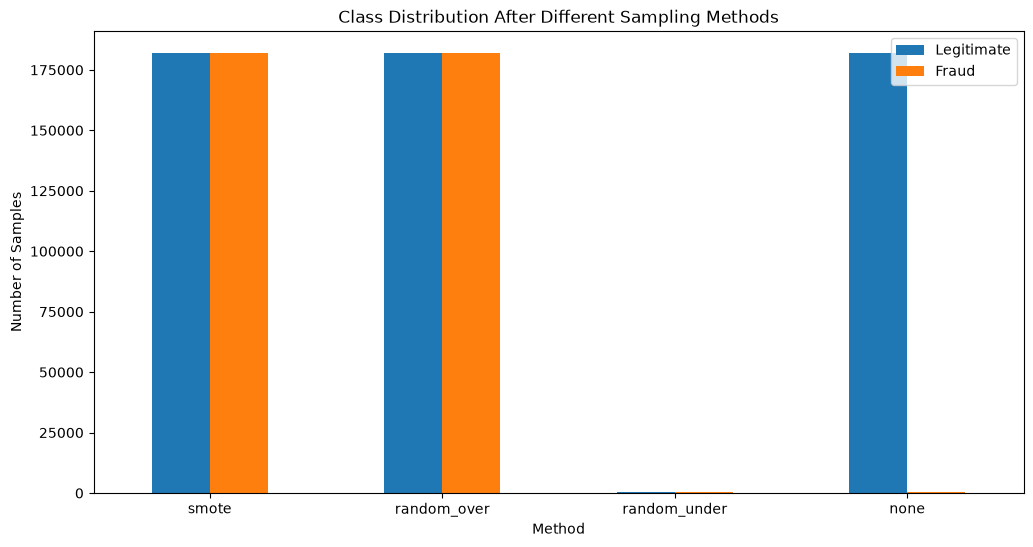

In [6]:
sampling_plot = sampling_comparison.set_index(
    "Method"
)[["Legitimate", "Fraud"]]

sampling_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Class Distribution After Different Sampling Methods")

plt.ylabel("Number of Samples")

plt.xticks(rotation=0)

plt.show()

## 5. Important Methodological Considerations

Sampling is performed only on training data.

Validation and test datasets must preserve their original
class distributions.

SMOTE is placed inside an imbalanced-learn Pipeline during
cross-validation to prevent information leakage between folds.

Sampling methods must be compared using validation metrics,
not training accuracy.

The final strategy will be selected based on fraud detection
performance and the business requirements.

In [7]:
print("Original Training Distribution:")
print(Counter(y_train))

print("\nValidation Distribution:")
print(Counter(y_validation))

print("\nTest Distribution:")
print(Counter(y_test))

print("\nSampling experiments completed on training data only.")

Original Training Distribution:
Counter({0: 181961, 1: 315})

Validation Distribution:
Counter({0: 45490, 1: 79})

Test Distribution:
Counter({0: 56864, 1: 98})

Sampling experiments completed on training data only.
